# NB4 · Learned graph (TCN-GAT) and injection benchmark

Guide sections "Detector: multi-scale graph model" (eq. 13), "Synthetic injection protocol", "Metrics" (eq. 17–18) and "Baselines, ablations and generalisation". This is the first place where accuracy against **known** types can be measured.

**Part A: the graph detector (guide eq. 13).**
- **TCN-GAT** for the 15 southern zones: a causal temporal convolutional network on each zone's past, plus graph attention over the *current* ρ of its neighbours (leave-one-zone-out).
- Same-city zones are neighbours. Cross-city edges are **learned** (GDN-style node embeddings, top-k = 4 by cosine similarity).
- **Hybrid (D59): LightGBM + learned-graph correction.** The same network receives NB3's LightGBM forecast and learns a correction to it. The graph attention reads each neighbour's current value *and* its current LightGBM residual. The output is the forecast plus the correction, and the correction starts at zero.
- Ablations: the TCN without the graph, the hybrid without the graph (LightGBM + TCN correction), and the plain average of LightGBM and TCN-GAT.
- All networks are trained with the masked Huber loss and the same two-fold temporal cross-fitting as NB3's LightGBM. They are compared on clean-data error and on NB3's residual-hierarchy test.
- **The main detector and every detector's event formation** (score smoothing, threshold percentile, merge gap) are chosen on separate development datasets (seeds 100–104) by `tools/dev_select_detector.py` (D60). The choice is stored in `results/benchmark_v1/dev_selection.json`. The benchmark seeds 0–9 are never used for any choice.

**Part B: injection benchmark.**
- Observed signatures are injected into clean zone-time only, at **1 %, 3 % and 7 %**, over **10 seeds**: A1–A3 and G1–G4, plus two untyped cases required by F29 (an unflagged multi-zone shock) and F32 (a partial outage).
- The whole method is rerun on each injected dataset: rules → label model → detector → end model → fusion.
- Training and validation use Sep 2022 – Jun 2023 (β is tuned there); the test period is Jul 2023 – May 2024.
- **Detection** (Table 5, Fig 9): event-wise precision, recall and F1 (eq. 17), and step-wise AUC-PR.
- **Attribution** (Table 6, Figs 10–11): macro-F1, per-class F1, ECE (eq. 18) and Brier.
- **Ablations** (Table 7): pipeline stages, rule families, hierarchy, scale, graph, forecast vs nowcast, and threshold sensitivity (ε, hold length, τ).
- **Hard negatives:** false alarms on Ramadan, Eid, holidays and weekends.

**Baselines:** the rule engine alone, STL + MAD, Isolation Forest, LOF and majority vote (guide list). Not run: Matrix Profile, USAD, TranAD, Anomaly Transformer, TimesNet, GDN, MTAD-GAT and Snorkel (D57).

**Run on Colab (GPU recommended):**
1. *Runtime → Change runtime type → T4 GPU*.
2. *Run all*.

Every injected dataset is saved to `results/benchmark_v1/runs/` as soon as it finishes. If Colab disconnects, *Run all* again: finished runs are skipped. Expect about 6–8 min per injected dataset on Colab (30 datasets at the default settings), plus about 15 min for the real data and the threshold sweep, plus about 20 min of network training on a GPU if the models in `results/benchmark_v1/models/` are missing. Set `QUICK = True` for a 10-minute test run.

- **Scoring area:** the rule-based clean region, the same for every detector (D60). Excluding NB3's detector candidates would hide the false alarms of one detector only.

**Decisions:** D53 (TCN-GAT), D54 (injection protocol and evaluation scope), D55 (one network on ρ, not per band), D56 (β tuning and abstention on injected data), D57 (baselines not run), D58 (rerun and caching protocol), D59 (hybrid), D60 (development selection, event formation, scoring area).

In [1]:
import sys, subprocess, json, time, pickle, os
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm==4.6.0", "PyWavelets", "statsmodels", "openpyxl"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import torch, lightgbm, pywt, statsmodels
from scipy.stats import wilcoxon
import rules_v1 as R1, detector as D, end_model as EM, label_model as LM, graph_model as G, benchmark as B, inject as INJ
from viz import COL, LABEL_COL, savefig
LABEL_COL = {**LABEL_COL, "N": "#9AA0A6"}

# ---------------------------------------------------------------- configuration
RATES = [0.01, 0.03, 0.07]          # guide: 1 %, 3 %, 7 % of clean zone-time
SEEDS = list(range(10))             # guide: 10 seeds
FAMILY_ABLATION_RATE = 0.03         # rule-family ablation of the label model runs at this rate only
SENS_SEEDS = [0, 1, 2]              # threshold sensitivity (rules + label model only), at 3 %
QUICK = False                       # True: one rate, two seeds, short TCN training (tests the notebook in ~10 min)
if QUICK:
    RATES, SEEDS, SENS_SEEDS = [0.03], [0, 1], [0]
TCN_CFG = dict(epochs=40, patience=6) if not QUICK else dict(epochs=2, max_batches=10)
BASELINES = B.BASELINES

XLSX = ROOT / "data" / "raw" / "Data Morocco.xlsx"
OUT = ROOT / "results" / ("benchmark_v1" if not QUICK else "benchmark_quick")
RUNS, MODELS = OUT / "runs", OUT / "models"
for d in (RUNS, MODELS): d.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures" if not QUICK else OUT / "figures"     # QUICK figures never overwrite the real ones
FIG.mkdir(parents=True, exist_ok=True)
SEL_FILE = ROOT / "results" / "benchmark_v1" / "dev_selection.json"     # tools/dev_select_detector.py (D60)
if SEL_FILE.exists():
    SEL = json.loads(SEL_FILE.read_text()); MAIN, SETTINGS = SEL["main"], SEL["settings"]
else:
    SEL, MAIN, SETTINGS = None, B.V_HYB, {}
    print("WARNING: no dev_selection.json (run tools/dev_select_detector.py): hybrid main detector, NB3 event formation")
print("main detector:", MAIN); print("event formation (w, q, gap):", SETTINGS)
DEVICE = G.default_device()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
print("ROOT =", ROOT, "| device", DEVICE, "| lightgbm", lightgbm.__version__, "| torch", torch.__version__, "| QUICK", QUICK)
T0 = time.time()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
main detector: TCN-GAT, hierarchy, multi-scale
event formation (w, q, gap): {'Isolation Forest': {'w': 3, 'q': 99.5, 'gap': 3}, 'LOF': {'w': 24, 'q': 99.8, 'gap': 12}, 'LightGBM + learned-graph correction, hierarchy, multi-scale': {'w': 24, 'q': 99.8, 'gap': 6}, 'LightGBM forecast, hierarchy, multi-scale': {'w': 24, 'q': 99.8, 'gap': 6}, 'STL + MAD': {'w': 24, 'q': 99.8, 'gap': 12}, 'TCN-GAT, hierarchy, multi-scale': {'w': 24, 'q': 99.9, 'gap': 12}, 'mean(LightGBM, TCN-GAT), hierarchy, multi-scale': {'w': 48, 'q': 99.8, 'gap': 12}}
ROOT = /content/drive/MyDrive/grid-event-or-data-artefact | device cuda | lightgbm 4.6.0 | torch 2.14.1+cu130 | QUICK False


## 1. Real data and the clean region (where injection is allowed and predictions are scored)

In [2]:
res = R1.build(XLSX)
items = res["items"]
cat = pd.read_csv(ROOT / "results" / "catalogue_v1" / "items.csv", parse_dates=["start", "end"])
assert (items.item_id.values == cat.item_id.values).all(), "rule engine output differs from catalogue_v1"
P = D.build_panel(res["data"], res["exp"], res["masks"], "south")
CLEAN = B.clean_region(P, None)      # rule-based: the same scoring area for every detector (D60)
fold = P["rho"].index >= D.SPLIT
print(f"south panel {P['rho'].shape}; clean share of zone-steps: all {CLEAN.to_numpy().mean():.3f}, "
      f"train {CLEAN.to_numpy()[~fold].mean():.3f}, test {CLEAN.to_numpy()[fold].mean():.3f}")

south panel (88890, 15); clean share of zone-steps: all 0.819, train 0.770, test 0.863


## 2. Predictors trained once on the real data

- **LightGBM forecast and nowcast** (NB3, D39–D41).
- **TCN** (no graph) and **TCN-GAT** (learned graph, guide eq. 13; D53).
- **Hybrids** on the LightGBM forecast (D59): **LightGBM + learned-graph correction** and its no-graph ablation **LightGBM + TCN correction**.

All are cross-fitted in two temporal folds and trained on rule-clean steps only. During the benchmark they only *predict* the injected series: each half is predicted by models trained on the other half of the real data, so they have never seen an injected event.

LightGBM models loaded from /content/drive/MyDrive/grid-event-or-data-artefact/results/benchmark_v1/models/lightgbm_models.pkl
TCN loaded from /content/drive/MyDrive/grid-event-or-data-artefact/results/benchmark_v1/models/tcn.pt
TCN-GAT loaded from /content/drive/MyDrive/grid-event-or-data-artefact/results/benchmark_v1/models/tcn_gat.pt
LGB + TCN loaded from /content/drive/MyDrive/grid-event-or-data-artefact/results/benchmark_v1/models/hybrid_tcn.pt
LGB + GAT loaded from /content/drive/MyDrive/grid-event-or-data-artefact/results/benchmark_v1/models/hybrid_gat.pt


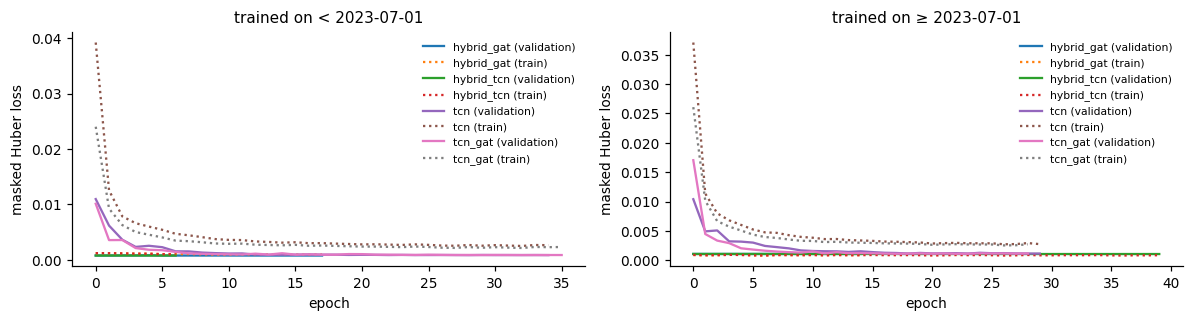

In [3]:
f = MODELS / "lightgbm_models.pkl"
LGB = None
if f.exists():
    try:   # pickled locally with numpy 1.26 / scikit-learn 1.5 / LightGBM 4.6.0; refit if this environment cannot read it
        LGB = pickle.load(open(f, "rb")); print("LightGBM models loaded from", f)
        assert set(LGB) == {"forecast", "nowcast"}
        _ = D.apply_rho_models(P, LGB["forecast"], "forecast")     # smoke test: the loaded models must predict
    except Exception as e:
        print("could not use the saved LightGBM models (", type(e).__name__, e, "): refitting"); LGB = None
if LGB is None:
    t = time.time()
    LGB = {k: D.fit_rho_models(P, k, backend="lightgbm") for k in ("forecast", "nowcast")}
    pickle.dump(LGB, open(f, "wb")); print(f"LightGBM fitted in {time.time() - t:.0f} s")

PF = D.apply_rho_models(P, LGB["forecast"], "forecast")          # base of the hybrids
GM, HIST = {}, []
for name, fname, graph, hybrid in (("TCN", "tcn", False, False), ("TCN-GAT", "tcn_gat", True, False),
                                   ("LGB + TCN", "hybrid_tcn", False, True), ("LGB + GAT", "hybrid_gat", True, True)):
    f = MODELS / f"{fname}.pt"
    if f.exists():
        GM[name] = G.load_models(f, P, device=DEVICE); print(name, "loaded from", f)
    else:
        t = time.time()
        GM[name], h = G.fit_graph_models(P, graph=graph, cfg=TCN_CFG, device=DEVICE, log=True, base=PF if hybrid else None)
        G.save_models(GM[name], f, TCN_CFG); h.to_csv(MODELS / f"{f.stem}_history.csv", index=False)
        print(f"{name} trained in {time.time() - t:.0f} s")
for f in MODELS.glob("*_history.csv"):
    HIST.append(pd.read_csv(f).assign(model=f.stem.replace("_history", "")))
if HIST:
    hist = pd.concat(HIST)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3))
    for (m, tf), g in hist.groupby(["model", "train_fold"]):
        axs[int(tf)].plot(g.epoch, g.val, label=f"{m} (validation)")
        axs[int(tf)].plot(g.epoch, g.train, ls=":", label=f"{m} (train)")
    for k, ax in enumerate(axs):
        ax.set_title(f"trained on {'≥' if k else '<'} {D.SPLIT.date()}"); ax.set_xlabel("epoch"); ax.set_ylabel("masked Huber loss"); ax.legend(fontsize=7)
    fig.tight_layout(); plt.show()

In [4]:
PRED = {"LGB forecast": PF,
        "LGB nowcast (all zones, no learned edges)": D.apply_rho_models(P, LGB["nowcast"], "nowcast"),
        "TCN (no graph)": G.apply_graph_models(P, GM["TCN"]),
        "TCN-GAT (learned graph)": G.apply_graph_models(P, GM["TCN-GAT"]),
        "LightGBM + TCN correction (no graph)": G.apply_graph_models(P, GM["LGB + TCN"], base=PF),
        "LightGBM + learned-graph correction (hybrid)": G.apply_graph_models(P, GM["LGB + GAT"], base=PF)}
PRED["mean(LightGBM, TCN-GAT)"] = (PF + PRED["TCN-GAT (learned graph)"]) / 2
clean = ~P["mask"]
rows = []
for name, pr in PRED.items():
    e = (P["rho"] - pr).where(clean)
    for per, sel in [("all", slice(None)), ("Jul 2023 +", e.index >= D.SPLIT)]:
        v = e.loc[sel].abs().stack()
        rows.append(dict(predictor=name, period=per, MAE=v.mean(), median_abs=v.median(), RMSE=np.sqrt((v ** 2).mean())))
pred_cmp = pd.DataFrame(rows).round(4)
pred_cmp.to_csv(OUT / "predictor_comparison.csv", index=False)

# NB3's residual-hierarchy test (raw band) for every predictor
south_items = items[(items.system == "south") & items.kind.isin(["dead", "fill"])].copy()
ncity = {c: sum(1 for z in P["rho"].columns if P["city"][z] == c) for c in set(P["city"].values())}
def expected_level(r):
    if r.n_cities >= 2: return "g"
    if r.n_zones >= 2: return "u" if r.n_zones / ncity[r.cities] >= 0.9 else None
    return "v"
south_items["expected_level"] = [expected_level(r) for r in south_items.itertuples()]
south_items.loc[south_items.start < P["rho"].index[0] + pd.Timedelta(days=D.WARMUP_DAYS), "expected_level"] = None
hrows = []
for name, pr in PRED.items():
    S = D.level_scores(P, P["rho"] - pr, bands_used=["raw"])["raw"]
    tops = []
    for r in south_items.itertuples():
        if r.expected_level is None: tops.append(None); continue
        sl = slice(r.start, r.end - pd.Timedelta("10min")); zs = r.zones.split(","); cs = sorted(set(P["city"][z] for z in zs))
        vals = [S["g"][sl].max(), S["u"].loc[sl, cs].max().max(), S["v"].loc[sl, zs].max().max()]
        tops.append("guv"[int(np.nanargmax(vals))] if np.isfinite(vals).any() else None)
    south_items["top"] = tops
    ok = south_items.expected_level.notna()
    for k in ["dead", "fill"]:
        for lv in "guv":
            sel = ok & (south_items.kind == k) & (south_items.expected_level == lv)
            if sel.any():
                hrows.append(dict(predictor=name, kind=k, level=lv, n=int(sel.sum()), correct=(south_items.top[sel] == lv).mean()))
    hrows.append(dict(predictor=name, kind="all", level="all", n=int(ok.sum()), correct=(south_items.top[ok] == south_items.expected_level[ok]).mean()))
hier_cmp = pd.DataFrame(hrows).round(3)
hier_cmp.to_csv(OUT / "hierarchy_consistency_by_predictor.csv", index=False)
display(pred_cmp.pivot_table(index="predictor", columns="period", values="MAE"))
display(hier_cmp.pivot_table(index=["kind", "level", "n"], columns="predictor", values="correct"))

period,Jul 2023 +,all
predictor,,
LGB forecast,0.0278,0.0288
"LGB nowcast (all zones, no learned edges)",0.0282,0.0292
LightGBM + TCN correction (no graph),0.0278,0.0288
LightGBM + learned-graph correction (hybrid),0.0278,0.0288
TCN (no graph),0.0289,0.0299
TCN-GAT (learned graph),0.0296,0.0294
"mean(LightGBM, TCN-GAT)",0.0278,0.0282


predictor       LGB forecast  LGB nowcast (all zones, no learned edges)  LightGBM + TCN correction (no graph)  LightGBM + learned-graph correction (hybrid)  TCN (no graph)  TCN-GAT (learned graph)  \
kind level n                                                                                                                                                                                           
all  all   206         0.714                                      0.694                                 0.689                                         0.709           0.767                    0.733   
dead g     3           1.000                                      1.000                                 1.000                                         1.000           0.667                    0.667   
     v     71          0.915                                      0.915                                 0.915                                         0.915           0.915                    0.915   
fill g     6           0.167                                      0.167                                 0.167                                         0.167           0.167                    0.333   
     u     40          0.550                                      0.450                                 0.500                                         0.525           0.600                    0.475   
     v     86          0.651                                      0.651                                 0.616                                         0.651           0.767                    0.733   

predictor       mean(LightGBM, TCN-GAT)  
kind level n                             
all  all   206                    0.714  
dead g     3                      0.667  
     v     71                     0.915  
fill g     6                      0.333  
     u     40                     0.550  
     v     86                     0.651

### The learned graph
Rows are receiving zones and columns are sending zones. Grey cells are edges the model can use: same city, plus the 4 learned cross-city neighbours. The colour shows the mean attention weight on clean steps, averaged over both folds and both heads. The figure shows the graph of the TCN-GAT. The hybrid's correction stays close to zero (D59), so its attention is not interpretable; its cross-city edges are saved too.

saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E20_learned_graph.png


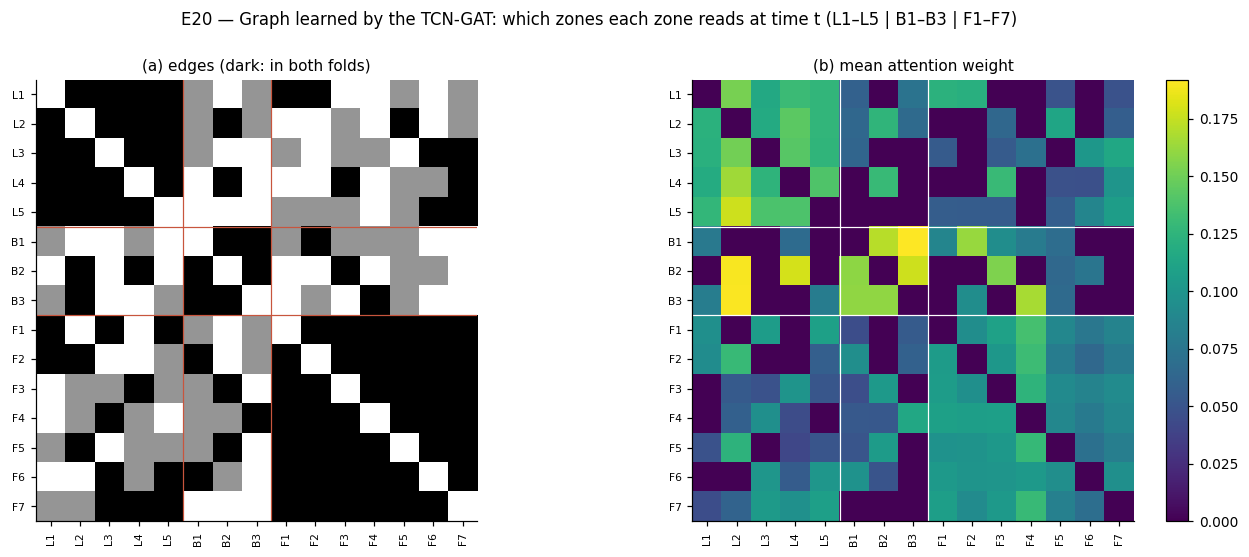

strongest learned cross-city edges:
to from  attention
B3   L2   0.191128
B2   L2   0.189988
B2   L4   0.179269
B3   F4   0.166795
B1   F2   0.161942
B2   F3   0.155046
L4   F3   0.129835
F2   L2   0.129499
L4   B2   0.129122
L2   B2   0.125582
mean attention per edge: same city 0.115, cross city 0.085


In [5]:
LGS = {"TCN-GAT": G.learned_graph(P, GM["TCN-GAT"]), "LGB + GAT": G.learned_graph(P, GM["LGB + GAT"], base=PF)}
GNAME = "TCN-GAT"
for k, lg in LGS.items():
    a_ = sum(a.astype(int) for a, _ in lg.values()); t_ = sum(t for _, t in lg.values()) / len(lg)
    e_ = [(i, j, float(t_.loc[i, j])) for i in t_.index for j in t_.columns if a_.loc[i, j] > 0 and P["city"][i] != P["city"][j]]
    pd.DataFrame(e_, columns=["to", "from", "attention"]).sort_values("attention", ascending=False).to_csv(
        OUT / f"learned_cross_city_edges_{k.replace(' + ', '_').replace('-', '_').lower()}.csv", index=False)
LG = LGS[GNAME]
zones = list(P["rho"].columns)
adj = sum(a.astype(int) for a, _ in LG.values()); att = sum(t for _, t in LG.values()) / len(LG)
fig, axs = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw=dict(width_ratios=[1, 1.15]))
axs[0].imshow(adj.values, cmap="Greys", vmin=0, vmax=2)
im = axs[1].imshow(att.values, cmap="viridis")
for ax, title in zip(axs, ["(a) edges (dark: in both folds)", "(b) mean attention weight"]):
    ax.set_xticks(range(len(zones))); ax.set_xticklabels(zones, rotation=90, fontsize=7)
    ax.set_yticks(range(len(zones))); ax.set_yticklabels(zones, fontsize=7); ax.set_title(title)
    for b in [4.5, 7.5]:
        ax.axhline(b, color="w" if ax is axs[1] else "#C8553D", lw=.8); ax.axvline(b, color="w" if ax is axs[1] else "#C8553D", lw=.8)
plt.colorbar(im, ax=axs[1], fraction=.046)
fig.suptitle("E20 — Graph learned by the TCN-GAT: which zones each zone reads at time t (L1–L5 | B1–B3 | F1–F7)", y=1.0)
fig.tight_layout(); savefig(fig, FIG, "E20_learned_graph"); plt.show()
cross = [(i, j, float(att.loc[i, j])) for i in zones for j in zones if adj.loc[i, j] > 0 and P["city"][i] != P["city"][j]]
edges = pd.DataFrame(cross, columns=["to", "from", "attention"]).sort_values("attention", ascending=False)
edges.to_csv(OUT / "learned_cross_city_edges.csv", index=False)
print("strongest learned cross-city edges:"); print(edges.head(10).to_string(index=False))
same = np.mean([att.loc[i, j] for i in zones for j in zones if adj.loc[i, j] > 0 and P["city"][i] == P["city"][j]])
print(f"mean attention per edge: same city {same:.3f}, cross city {edges.attention.mean():.3f}")

## 3. Injection protocol (D54)
Each event copies a signature seen in the data (`src/inject.py`). Events are placed round-robin over the types until the injected zone-steps reach the target share of clean zone-time. Each event blocks its zones for ±12 h, and multi-city events block every zone for ±3 h, so injected events do not touch each other. A whole-city fill is followed by a zero fill with probability 0.5: the compound A2 → A1 pattern of C05/C06 and C12.

264 events at 3 %, seed 0


,n,median_h,zone_steps,mechanisms
type,,,,
A1,34,1.500000,7519,"zero, zero (after fill)"
A2,29,4.000000,6091,"hold, linear"
A3,29,2.833333,515,"hold, linear"
G1,29,4.000000,11068,floor
G2,28,1.416667,1532,floor
G3,29,5.000000,1740,floor
G4,28,3.000000,533,floor
U_PARTIAL,29,2.333333,494,"x0.10, x0.11, x0.14, x0.16, x0.18, x0.20, x0.21, x0.24, ..."
U_SHOCK,29,1.500000,3961,"x0.51, x0.52, x0.53, x0.55, x0.56, x0.57, x0.60, x0.62, ..."


saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E21_injected_signatures.png


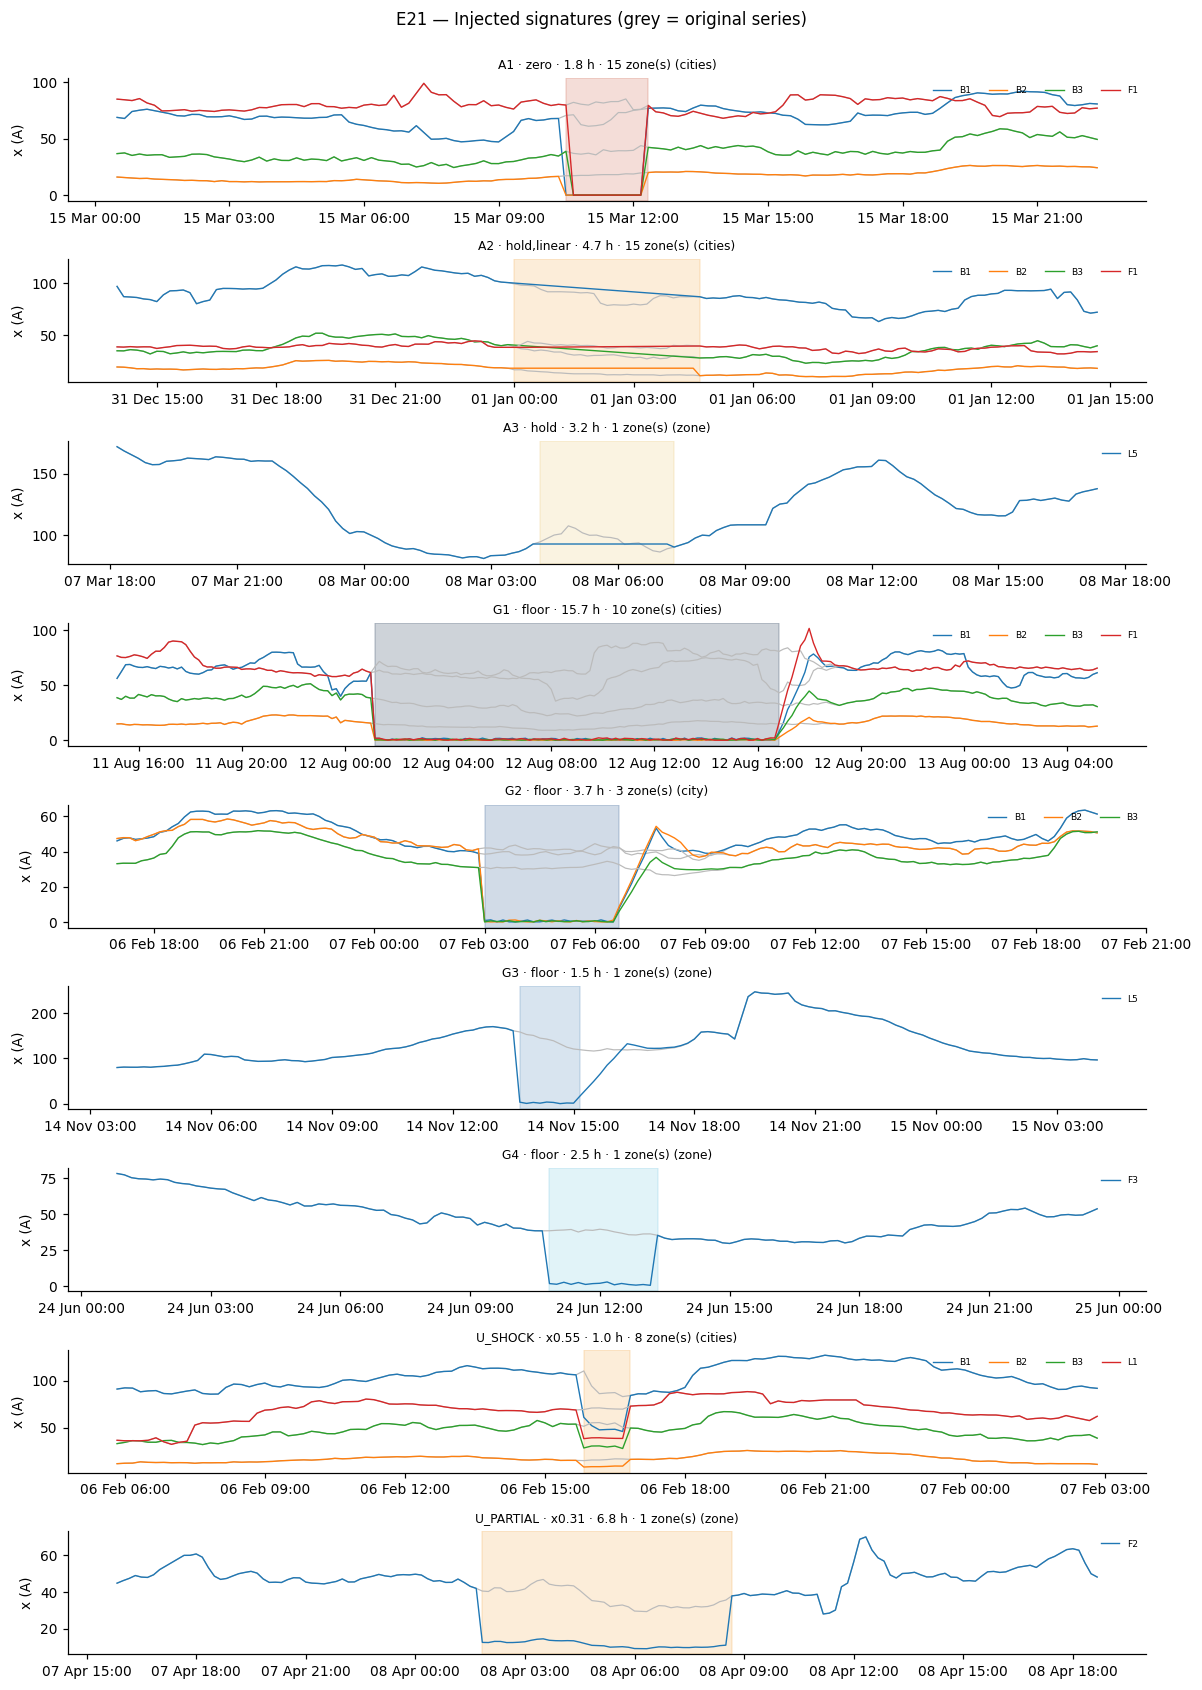

In [6]:
ZMAP = INJ.zone_map(res["data"], B.SOUTH, R1.CITY_SHORT)
INJECTOR = INJ.Injector(res["data"], res["exp"], CLEAN, ZMAP)
def make_dataset(rate, seed):
    return INJECTOR.sample(np.ones(len(P["rho"].index), bool), rate, np.random.default_rng([int(round(rate * 1000)), seed]))
ex_data, ex_truth = make_dataset(0.03, 0)
print(len(ex_truth), "events at 3 %, seed 0")
display(ex_truth.groupby("type").agg(n=("event_id", "size"), median_h=("duration_h", "median"), zone_steps=("zone_steps", "sum"),
                                     mechanisms=("mechanism", lambda m: ", ".join(sorted(set(",".join(m).split(",")))))))
show = ex_truth[ex_truth.type.isin(INJ.TYPES)].groupby("type").head(1).set_index("type").loc[[t for t in INJ.TYPES if t in set(ex_truth.type)]]
fig, axs = plt.subplots(len(show), 1, figsize=(11, 1.7 * len(show)))
for ax, (typ, r) in zip(np.atleast_1d(axs), show.iterrows()):
    zs = r.zones.split(",")[:4]
    a, b = r.start - pd.Timedelta(hours=10), r.end_affected + pd.Timedelta(hours=10)
    for z in zs:
        c, col = ZMAP[z]
        ax.plot(res["data"][c][col][a:b], color="#bbb", lw=.8)
        ax.plot(ex_data[c][col][a:b], lw=.9, label=z)
    ax.axvspan(r.start, r.end, color=LABEL_COL.get(typ, "#F2A541"), alpha=.2)
    ax.set_title(f"{typ} · {r.mechanism} · {r.duration_h:.1f} h · {r.n_zones} zone(s) ({r.pattern})", fontsize=8)
    ax.set_ylabel("x (A)"); ax.legend(fontsize=6, ncol=4, loc="upper right"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle("E21 — Injected signatures (grey = original series)", y=1.0)
fig.tight_layout(); savefig(fig, FIG, "E21_injected_signatures"); plt.show()

## 4. Benchmark runs (resumable)
For each rate and seed: inject, rerun the whole pipeline, score. Results go to `runs/` immediately.

In [7]:
bench = B.Benchmark(res["raw"], P, None, LGB, GM, gb_backend="lightgbm", log=False, main=MAIN, settings=SETTINGS)
t = time.time(); REAL = bench.pipeline(res["data"], seed=0, baselines=BASELINES)      # the uninjected data (also used in §8b and §9)
bench.set_background(REAL)
print(f"real data through the whole method: {time.time() - t:.0f} s; detector-only candidates of the main detector: {len(REAL['det_only'])}")
REAL_ALARMS = {k: len(d) for k, d in REAL["DET"].items()}
todo = [(r, s) for r in RATES for s in SEEDS]
t_start = time.time(); done = 0
for k, (rate, seed) in enumerate(todo):
    tag = f"r{int(round(rate * 100)):02d}_s{seed:02d}"
    if (RUNS / f"{tag}_info.json").exists():
        continue
    t = time.time()
    data_inj, truth = make_dataset(rate, seed)
    out = bench.run(data_inj, truth, seed=seed, baselines=BASELINES, family_ablation=(rate == FAMILY_ABLATION_RATE))
    truth.to_csv(RUNS / f"{tag}_truth.csv", index=False)
    out["detection"].to_csv(RUNS / f"{tag}_detection.csv", index=False)
    out["auc"].to_csv(RUNS / f"{tag}_auc.csv", index=False)
    out["events"].to_csv(RUNS / f"{tag}_events.csv", index=False)
    out["pred"].to_csv(RUNS / f"{tag}_pred.csv", index=False)
    (RUNS / f"{tag}_info.json").write_text(json.dumps({**out["info"], "rate": rate, "seed": seed}, default=str))
    done += 1
    left = sum(1 for r, s in todo if not (RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_info.json").exists())
    print(f"{tag}: {len(truth)} events, {time.time() - t:.0f} s | {left} left, about {left * (time.time() - t_start) / done / 60:.0f} min", flush=True)
print("all runs present:", all((RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_info.json").exists() for r, s in todo))

real data through the whole method: 212 s; detector-only candidates of the main detector: 70
r07_s02: 575 events, 293 s | 7 left, about 34 min
r07_s03: 505 events, 281 s | 6 left, about 29 min
r07_s04: 581 events, 289 s | 5 left, about 24 min
r07_s05: 597 events, 281 s | 4 left, about 19 min
r07_s06: 629 events, 315 s | 3 left, about 15 min
r07_s07: 585 events, 294 s | 2 left, about 10 min
r07_s08: 509 events, 280 s | 1 left, about 5 min
r07_s09: 594 events, 291 s | 0 left, about 0 min
all runs present: True


In [8]:
def load(kind):
    out = []
    for r, s in todo:
        f = RUNS / f"r{int(round(r * 100)):02d}_s{s:02d}_{kind}.csv"
        if f.exists():
            out.append(pd.read_csv(f).assign(rate=r, seed=s))
    return pd.concat(out, ignore_index=True)
DET, AUC, EV, TRUTH = load("detection"), load("auc"), load("events"), load("truth")
print(len(DET.groupby(["rate", "seed"])), "runs;", len(TRUTH), "injected events;", TRUTH.type.value_counts().to_dict())
def ms(x):
    x = pd.Series(x).dropna()
    return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}" if len(x) > 1 else (f"{x.mean():.3f}" if len(x) else "n/a")

30 runs; 8526 injected events; {'A1': 1127, 'G1': 930, 'A2': 927, 'U_SHOCK': 926, 'G4': 926, 'G3': 923, 'A3': 923, 'U_PARTIAL': 923, 'G2': 921}


## 5. Detection (Table 5, Fig 9)
- Test period (Jul 2023 – May 2024), mean ± standard deviation over seeds.
- **F1 follows the guide's eq. 17:** a predicted event counts if it overlaps an injected event in time, including the restoration tail.
- **Every alarm counts (primary, conservative):** a detection in rule-clean time that matches no injected event is a false alarm, even if it is a real but unlabelled anomaly of the series (about half of NB3's real-data candidates were surges or partial drops). The development selection used this F1, so noisy settings cannot win.
- **F1_own_background_excluded:** the same, but each method's own detections on the uninjected series are not scored, exactly as real rule states are not scored for the rules (D60). `real_data_alarms` gives the number of detections on the uninjected series, so noise stays visible.
- **F1_zone_strict** also requires a shared zone. The two differ mainly because a multi-city event shifts the region median g, which makes the *unaffected* city look anomalous at the city level. Per-type recall is zone-strict.
- Wilcoxon signed-rank test over seeds: ours vs the best baseline, and the main detector vs each other detector variant (alone).
- Every tuned detector (main candidates and baselines) uses the event formation chosen for it on the development seeds (D60). Ablations use the main detector's.

,rate,method,F1,precision,recall,F1_zone_strict,AUC_PR,F1_own_background_excluded,real_data_alarms,start_err_min
0,1%,ours (rules + detector),0.721 ± 0.047,0.646 ± 0.079,0.824 ± 0.035,0.628 ± 0.053,0.898 ± 0.043,0.896 ± 0.020,70.0,0.0
1,1%,rules only (rule engine v1),0.863 ± 0.032,1.000 ± 0.000,0.760 ± 0.049,0.863 ± 0.032,0.853 ± 0.059,0.863 ± 0.032,NaN,0.0
2,1%,"TCN-GAT, hierarchy, multi-scale",0.644 ± 0.067,0.583 ± 0.101,0.730 ± 0.037,0.615 ± 0.056,0.547 ± 0.062,0.817 ± 0.036,191.0,168.0
3,1%,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",0.655 ± 0.050,0.639 ± 0.076,0.676 ± 0.043,0.626 ± 0.048,0.521 ± 0.081,0.786 ± 0.024,131.0,222.0
4,1%,"LightGBM + learned-graph correction, hierarchy, multi-scale",0.627 ± 0.051,0.581 ± 0.067,0.685 ± 0.042,0.616 ± 0.048,0.595 ± 0.071,0.791 ± 0.029,150.0,112.0
5,1%,"LightGBM + TCN correction (no graph), hierarchy, multi-s...",0.645 ± 0.038,0.696 ± 0.052,0.602 ± 0.034,0.632 ± 0.035,0.593 ± 0.072,0.736 ± 0.034,93.0,95.0
6,1%,"LightGBM forecast, hierarchy, multi-scale",0.623 ± 0.055,0.574 ± 0.069,0.685 ± 0.046,0.611 ± 0.051,0.592 ± 0.071,0.793 ± 0.035,152.0,110.0
7,1%,"TCN-GAT, hierarchy, multi-scale (NB3 event formation)",0.365 ± 0.063,0.231 ± 0.050,0.889 ± 0.049,0.337 ± 0.058,0.541 ± 0.057,0.805 ± 0.064,639.0,120.0
8,1%,"LightGBM forecast, hierarchy, multi-scale (NB3 event for...",0.451 ± 0.061,0.311 ± 0.059,0.844 ± 0.028,0.427 ± 0.052,0.606 ± 0.067,0.836 ± 0.034,454.0,110.0
9,1%,single scale (raw band),0.595 ± 0.046,0.510 ± 0.067,0.725 ± 0.043,0.569 ± 0.043,0.566 ± 0.075,0.789 ± 0.039,206.0,100.0


,rate,best_baseline,ours_F1,baseline_F1,wilcoxon_p,n_seeds
0,1%,rules only (rule engine v1),0.7209,0.8631,0.0020,10
1,3%,rules only (rule engine v1),0.8755,0.8794,0.6250,10
2,7%,rules only (rule engine v1),0.9057,0.8959,0.0020,10
3,1%,"main detector vs mean(LightGBM, TCN-GAT), hierarchy, mul...",0.6438,0.6549,0.5566,10
4,1%,"main detector vs LightGBM + learned-graph correction, hi...",0.6438,0.6273,0.3223,10
5,1%,"main detector vs LightGBM + TCN correction (no graph), h...",0.6438,0.6449,1.0000,10
6,1%,"main detector vs LightGBM forecast, hierarchy, multi-scale",0.6438,0.6230,0.1602,10
7,1%,main detector vs STL + MAD,0.6438,0.6249,0.4922,10
8,1%,main detector vs Isolation Forest,0.6438,0.2107,0.0020,10
9,1%,main detector vs LOF,0.6438,0.5696,0.0098,10


recall_zone  recall_A1  recall_A2  recall_A3  recall_G1  recall_G2  recall_G3  recall_G4  recall_U_SHOCK  recall_U_PARTIAL  recall_bgx
rate method                                                                                                                                                                                              
0.01 LGB nowcast (raw, hierarchy)                                        0.550      0.960      0.618      0.000        1.0      0.685      0.905      0.804           0.000             0.050       0.548
     LightGBM + TCN correction (no graph), hierarchy, multi-scale        0.595      1.000      0.677      0.082        1.0      0.780      0.938      0.824           0.010             0.107       0.593
     LightGBM + learned-graph correction, hierarchy, multi-scale         0.679      1.000      0.838      0.132        1.0      1.000      0.975      0.926           0.130             0.233       0.664
     LightGBM forecast, hierarchy, multi-scale                           0.679      1.000      0.838      0.148        1.0      1.000      0.975      0.926           0.130             0.213       0.664
     LightGBM forecast, hierarchy, multi-scale (NB3 event form...        0.839      1.000      0.967      0.457        1.0      1.000      1.000      1.000           0.753             0.406       0.802
     TCN-GAT, hierarchy, multi-scale                                     0.723      1.000      0.888      0.252        1.0      1.000      1.000      0.975           0.302             0.180       0.695
     TCN-GAT, hierarchy, multi-scale (NB3 event formation)               0.877      1.000      0.967      0.507        1.0      1.000      1.000      1.000           0.925             0.534       0.808
     mean(LightGBM, TCN-GAT), hierarchy, multi-scale                     0.661      1.000      0.838      0.148        1.0      1.000      0.975      0.926           0.078             0.127       0.651
     ours (rules + detector)                                             0.824      1.000      1.000      1.000        1.0      1.000      1.000      1.000           0.302             0.180       0.816
     rules only (rule engine v1)                                         0.760      1.000      1.000      1.000        1.0      0.900      1.000      1.000           0.000             0.000       0.760
     single scale (raw band)                                             0.712      1.000      0.930      0.302        1.0      1.000      1.000      1.000           0.142             0.148       0.686
0.03 LGB nowcast (raw, hierarchy)                                        0.575      0.975      0.580      0.071        1.0      0.788      0.831      0.726           0.000             0.066       0.587
     LightGBM + TCN correction (no graph), hierarchy, multi-scale        0.629      0.992      0.608      0.147        1.0      0.894      0.896      0.841           0.023             0.133       0.644
     LightGBM + learned-graph correction, hierarchy, multi-scale         0.692      1.000      0.731      0.208        1.0      0.973      0.947      0.915           0.169             0.162       0.699
     LightGBM forecast, hierarchy, multi-scale                           0.691      1.000      0.725      0.215        1.0      0.973      0.947      0.915           0.163             0.162       0.696
     LightGBM forecast, hierarchy, multi-scale (NB3 event form...        0.801      1.000      0.855      0.360        1.0      1.000      1.000      1.000           0.591             0.320       0.775
     TCN-GAT, hierarchy, multi-scale                                     0.730      1.000      0.788      0.289        1.0      0.994      1.000      1.000           0.212             0.207       0.729
     TCN-GAT, hierarchy, multi-scale (NB3 event formation)               0.838      1.000      0.862      0.437        1.0      1.000      1.000      1.000           0.774             0.395       0.790
     mean(LightGBM, TCN-GAT

saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/fig9_detection.png


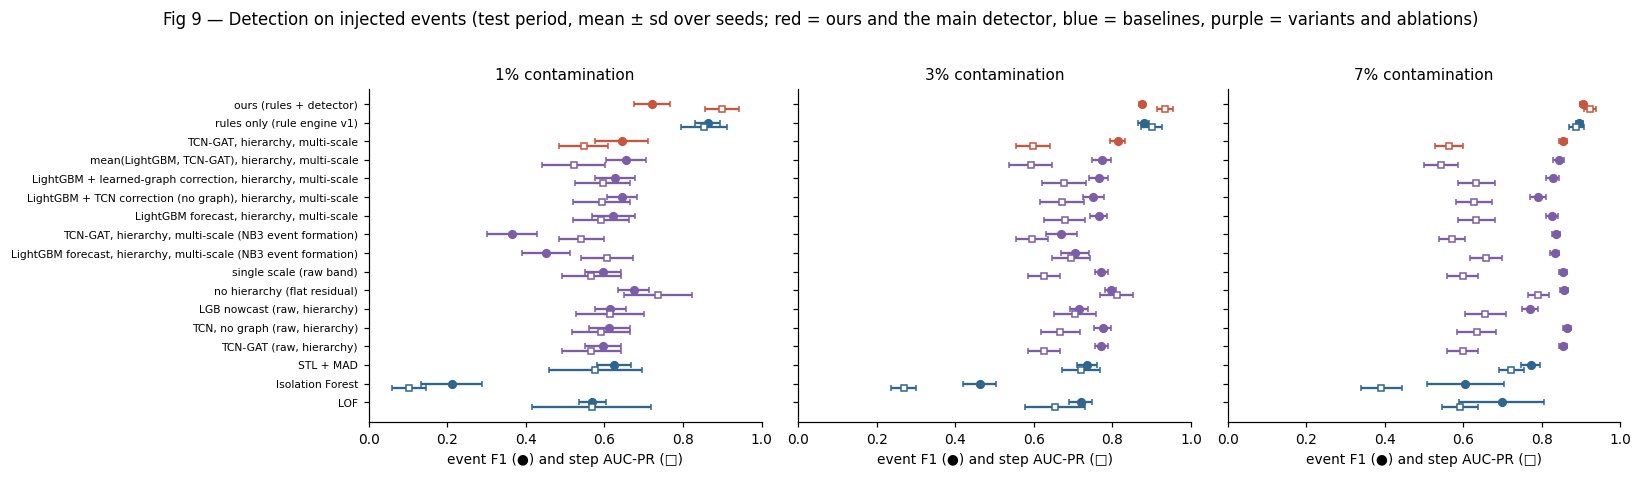

In [9]:
DETECTORS = [MAIN] + [v for v in (B.V_GAT, B.V_MEAN, B.V_HYB, B.V_HYB_NOG, B.V_LGB) if v != MAIN]   # graph detectors right after the main one
ORDER = ["ours (rules + detector)", "rules only (rule engine v1)"] + DETECTORS + [B.V_GAT_NB3, B.V_LGB_NB3, B.V_SINGLE, B.V_FLAT, B.V_NOW,
         B.V_TCN_RAW, B.V_GAT_RAW, "STL + MAD", "Isolation Forest", "LOF"]
BASE = ["rules only (rule engine v1)", "STL + MAD", "Isolation Forest", "LOF"]
dt = DET[DET.period == "test"].merge(AUC[AUC.period == "test"], on=["method", "period", "rate", "seed"], how="left")
rows = []
for rate in RATES:
    d = dt[dt.rate == rate]
    for m in [o for o in ORDER if o in set(d.method)]:
        g = d[d.method == m]
        rows.append(dict(rate=f"{rate:.0%}", method=m, F1=ms(g.f1), precision=ms(g.precision), recall=ms(g.recall), F1_zone_strict=ms(g.f1_zone), AUC_PR=ms(g.auc_pr),
                         F1_own_background_excluded=ms(g.f1_bgx) if "f1_bgx" in g else "n/a",
                         real_data_alarms=REAL_ALARMS.get(m, len(REAL["det_only"]) if m == "ours (rules + detector)" else np.nan),
                         start_err_min=round(g.start_err_min.median(), 0), F1_mean=g.f1.mean()))
table5 = pd.DataFrame(rows)
tests = []
for rate in RATES:
    d = dt[dt.rate == rate]
    best = d[d.method.isin(BASE)].groupby("method").f1.mean().idxmax()
    a = d[d.method == "ours (rules + detector)"].set_index("seed").f1; b = d[d.method == best].set_index("seed").f1
    a, b = a.align(b, join="inner")
    p = wilcoxon(a, b).pvalue if len(a) >= 6 and (a != b).any() else np.nan
    tests.append(dict(rate=f"{rate:.0%}", best_baseline=best, ours_F1=a.mean(), baseline_F1=b.mean(), wilcoxon_p=p, n_seeds=len(a)))
for rate in RATES:                                   # main detector vs every other detector variant, alone
    d = dt[dt.rate == rate]
    for other in [v for v in DETECTORS[1:] + ["STL + MAD", "Isolation Forest", "LOF"] if v in set(d.method)]:
        a = d[d.method == MAIN].set_index("seed").f1; b = d[d.method == other].set_index("seed").f1
        a, b = a.align(b, join="inner")
        p = wilcoxon(a, b).pvalue if len(a) >= 6 and (a != b).any() else np.nan
        tests.append(dict(rate=f"{rate:.0%}", best_baseline=f"main detector vs {other}", ours_F1=a.mean(), baseline_F1=b.mean(), wilcoxon_p=p, n_seeds=len(a)))
table5.drop(columns="F1_mean").to_csv(OUT / "table5_detection.csv", index=False)
pd.DataFrame(tests).to_csv(OUT / "table5_wilcoxon.csv", index=False)
display(table5.drop(columns="F1_mean")); display(pd.DataFrame(tests).round(4))

rec_cols = [c for c in DET.columns if c.startswith("recall_")]
rec = dt[dt.method.isin(["ours (rules + detector)", "rules only (rule engine v1)"] + DETECTORS + [B.V_GAT_NB3, B.V_LGB_NB3, B.V_NOW, B.V_SINGLE])]
rec_t = rec.groupby(["rate", "method"])[rec_cols].mean().round(3)
rec_t.to_csv(OUT / "detection_recall_by_type.csv"); display(rec_t)

fig, axs = plt.subplots(1, len(RATES), figsize=(5 * len(RATES), 4.2), sharey=True, squeeze=False)
for ax, rate in zip(axs[0], RATES):
    d = dt[dt.rate == rate]; ms_ = [o for o in ORDER if o in set(d.method)]
    for i, m in enumerate(ms_):
        g = d[d.method == m]
        col = "#C8553D" if (m.startswith("ours") or m == MAIN) else ("#2F6690" if m in BASE else "#7B5EA7")
        ax.errorbar(g.f1.mean(), i, xerr=g.f1.std(ddof=1) if len(g) > 1 else 0, fmt="o", color=col, ms=5, capsize=2)
        ax.errorbar(g.auc_pr.mean(), i + 0.25, xerr=g.auc_pr.std(ddof=1) if len(g) > 1 else 0, fmt="s", color=col, mfc="white", ms=4, capsize=2)
    ax.set_yticks(range(len(ms_))); ax.set_yticklabels(ms_, fontsize=7); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_title(f"{rate:.0%} contamination"); ax.set_xlabel("event F1 (●) and step AUC-PR (□)")
fig.suptitle("Fig 9 — Detection on injected events (test period, mean ± sd over seeds; red = ours and the main detector, blue = baselines, purple = variants and ablations)", y=1.02)
fig.tight_layout(); savefig(fig, FIG, "fig9_detection"); plt.show()

## 6. Attribution (Table 6, Figs 10–11)
- Scored on injected **typed** events that the full method detected. Each event takes the label of its best-overlapping predicted item. End-to-end numbers, which count missed events as wrong, are reported too.
- **β** for fusion (eq. 16) is tuned on the training period (Sep 2022 – Jun 2023), pooled over seeds at each rate, by macro-F1. It is then frozen for the test period (D56).
- On injected data, A1, G1 and G2 are no longer rare, so fusion is reported both with and without NB3's low-support abstention (D50).

In [10]:
CL = EM.EVENT_CLASSES
typed = EV[EV.type.isin(INJ.TYPED)].copy()
det_ev = typed[typed.detected].reset_index(drop=True)
P_q = det_ev[[f"q_{c}" for c in CL]].to_numpy(float)
P_f = det_ev[[f"f_{c}" for c in CL]].to_numpy(float)
P_fn = det_ev[[f"fn_{c}" for c in CL]].to_numpy(float)
BETAS = np.round(np.arange(0, 1.01, 0.1), 1)
beta_rows, BETA = [], {}
for rate in RATES:
    tr = (det_ev.rate == rate) & (det_ev.period == "train")
    for b in BETAS:
        for ab in [True, False]:
            p = B.fused(det_ev[tr], b, abstain_low=("A1", "G1", "G2") if ab else ())
            beta_rows.append(dict(rate=rate, beta=b, abstain=ab, **B.attribution_scores(det_ev.type[tr].to_numpy(), probs=p)))
bt = pd.DataFrame(beta_rows)
for rate in RATES:
    for ab in [True, False]:
        g = bt[(bt.rate == rate) & (bt.abstain == ab)]
        BETA[(rate, ab)] = float(g.loc[(g.macro_f1 - 1e-9 * (g.beta - 0.5).abs()).idxmax(), "beta"])
bt.to_csv(OUT / "beta_tuning_train_period.csv", index=False)
print("tuned beta (train period, by macro-F1):", {f"{r:.0%}, abstain={a}": b for (r, a), b in BETA.items()})

def labelers(sub):
    yield "majority vote (rules)", None, np.where(sub.mv.isin(CL), sub.mv, "N")
    yield "label model q", sub[[f"q_{c}" for c in CL]].to_numpy(float), None
    yield "end model f, no detector features", sub[[f"fn_{c}" for c in CL]].to_numpy(float), None
    yield "end model f, all features", sub[[f"f_{c}" for c in CL]].to_numpy(float), None
    r = sub.rate.iloc[0]
    yield "fusion, no detector features (β*)", B.fused(sub, BETA[(r, True)], f_prefix="fn_"), None
    yield "fusion (β*, D50 abstention)", B.fused(sub, BETA[(r, True)]), None
    yield "fusion (β*, no abstention)", B.fused(sub, BETA[(r, False)], abstain_low=()), None

rows = []
for (rate, seed), sub in det_ev[det_ev.period == "test"].groupby(["rate", "seed"]):
    for name, probs, labels in labelers(sub):
        rows.append(dict(rate=rate, seed=seed, labeler=name, **B.attribution_scores(sub.type.to_numpy(), probs=probs, labels=labels)))
att = pd.DataFrame(rows)
e2e = []
for (rate, seed), sub in typed[typed.period == "test"].groupby(["rate", "seed"]):
    d = sub[sub.detected]
    lab = pd.Series("missed", index=sub.index)
    if len(d):
        lab.loc[d.index] = np.array(CL)[B.fused(d, BETA[(rate, True)]).argmax(1)]
    e2e.append(dict(rate=rate, seed=seed, detected_share=sub.detected.mean(), end_to_end_accuracy=(lab == sub.type).mean()))
e2e = pd.DataFrame(e2e)
t6 = []
for rate in RATES:
    for name in att.labeler.unique():
        g = att[(att.rate == rate) & (att.labeler == name)]
        t6.append(dict(rate=f"{rate:.0%}", labeler=name, macro_F1=ms(g.macro_f1), accuracy=ms(g.accuracy), ECE=ms(g.ece) if "ece" in g else "n/a",
                       Brier=ms(g.brier) if "brier" in g else "n/a", **{f"F1_{c}": round(g[f"f1_{c}"].mean(), 3) for c in INJ.TYPED}))
table6 = pd.DataFrame(t6)
table6.to_csv(OUT / "table6_attribution.csv", index=False); e2e.to_csv(OUT / "end_to_end.csv", index=False)
display(table6)
display(e2e.groupby("rate")[["detected_share", "end_to_end_accuracy"]].agg(["mean", "std"]).round(3))

tuned beta (train period, by macro-F1): {'1%, abstain=True': 0.7, '1%, abstain=False': 0.9, '3%, abstain=True': 0.6, '3%, abstain=False': 0.7, '7%, abstain=True': 0.6, '7%, abstain=False': 0.3}


,rate,labeler,macro_F1,accuracy,ECE,Brier,F1_A1,F1_A2,F1_A3,F1_G1,F1_G2,F1_G3,F1_G4
0,1%,majority vote (rules),0.940 ± 0.054,0.938 ± 0.056,n/a,n/a,0.920,0.943,1.000,0.929,0.933,0.918,0.935
1,1%,label model q,0.934 ± 0.055,0.937 ± 0.052,0.068 ± 0.041,0.114 ± 0.079,0.895,0.943,1.000,0.929,0.922,0.918,0.935
2,1%,"end model f, no detector features",0.875 ± 0.090,0.882 ± 0.071,0.124 ± 0.040,0.200 ± 0.092,0.751,1.000,0.944,0.905,0.906,0.768,0.851
3,1%,"end model f, all features",0.845 ± 0.071,0.852 ± 0.054,0.107 ± 0.028,0.229 ± 0.086,0.757,1.000,0.929,0.898,0.844,0.678,0.812
4,1%,"fusion, no detector features (β*)",0.944 ± 0.037,0.945 ± 0.038,0.071 ± 0.033,0.109 ± 0.064,0.906,1.000,1.000,0.929,0.922,0.918,0.935
5,1%,"fusion (β*, D50 abstention)",0.944 ± 0.037,0.945 ± 0.038,0.074 ± 0.031,0.111 ± 0.063,0.906,1.000,1.000,0.929,0.922,0.918,0.935
6,1%,"fusion (β*, no abstention)",0.936 ± 0.051,0.935 ± 0.053,0.068 ± 0.034,0.112 ± 0.072,0.906,0.943,1.000,0.929,0.922,0.918,0.935
7,3%,majority vote (rules),0.921 ± 0.029,0.905 ± 0.034,n/a,n/a,0.815,0.927,0.993,0.862,0.961,0.938,0.952
8,3%,label model q,0.914 ± 0.029,0.905 ± 0.032,0.089 ± 0.027,0.172 ± 0.050,0.786,0.927,0.993,0.862,0.937,0.943,0.952
9,3%,"end model f, no detector features",0.899 ± 0.040,0.889 ± 0.042,0.076 ± 0.019,0.180 ± 0.057,0.771,0.983,0.993,0.882,0.917,0.855,0.894


detected_share        end_to_end_accuracy       
               mean    std                mean    std
rate                                                 
0.01            1.0  0.000               0.945  0.038
0.03            1.0  0.000               0.907  0.026
0.07            1.0  0.001               0.896  0.020

saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/fig10_11_attribution.png


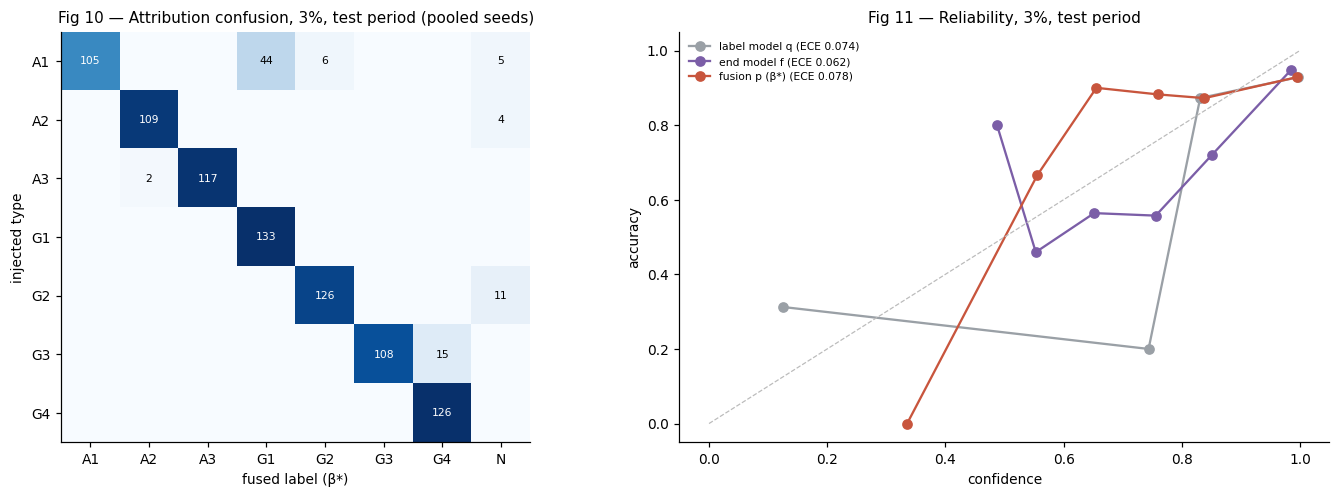

In [11]:
r0 = 0.03 if 0.03 in RATES else RATES[0]
sub = det_ev[(det_ev.rate == r0) & (det_ev.period == "test")]
pf = B.fused(sub, BETA[(r0, True)]); lab_p = np.array(CL)[pf.argmax(1)]
cm = pd.crosstab(pd.Categorical(sub.type, categories=INJ.TYPED), pd.Categorical(lab_p, categories=CL), dropna=False)
cm.to_csv(OUT / "fig10_confusion_fused.csv")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
norm = cm.div(cm.sum(axis=1).replace(0, 1), axis=0)
axs[0].imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
axs[0].set_xticks(range(len(CL))); axs[0].set_xticklabels(CL); axs[0].set_yticks(range(len(INJ.TYPED))); axs[0].set_yticklabels(INJ.TYPED)
for (i, j), v in np.ndenumerate(cm.values):
    if v: axs[0].text(j, i, v, ha="center", va="center", fontsize=7, color="w" if norm.values[i, j] > .6 else "k")
axs[0].set_xlabel("fused label (β*)"); axs[0].set_ylabel("injected type"); axs[0].set_title(f"Fig 10 — Attribution confusion, {r0:.0%}, test period (pooled seeds)")
bins = np.linspace(0, 1, 11)
for name, probs, col in [("label model q", sub[[f"q_{c}" for c in CL]].to_numpy(float), "#9AA0A6"),
                         ("end model f", sub[[f"f_{c}" for c in CL]].to_numpy(float), "#7B5EA7"), ("fusion p (β*)", pf, "#C8553D")]:
    conf = probs.max(1); corr = np.array(CL)[probs.argmax(1)] == sub.type.to_numpy()
    k = np.clip(np.digitize(conf, bins) - 1, 0, 9)
    xs = [conf[k == i].mean() for i in range(10) if (k == i).sum() >= 5]; ys = [corr[k == i].mean() for i in range(10) if (k == i).sum() >= 5]
    axs[1].plot(xs, ys, "o-", color=col, label=f"{name} (ECE {LM.ece(conf, corr):.3f})")
axs[1].plot([0, 1], [0, 1], color="#bbb", lw=.8, ls="--"); axs[1].set_xlabel("confidence"); axs[1].set_ylabel("accuracy"); axs[1].legend(fontsize=7)
axs[1].set_title(f"Fig 11 — Reliability, {r0:.0%}, test period")
fig.tight_layout(); savefig(fig, FIG, "fig10_11_attribution"); plt.show()

## 7. Ablations (Table 7)
- **(a) Pipeline:** rules (majority vote) → + label model → + end model without detector features → + detector features. These are scored on attribution, at the 3 % rate, in the test period.
- **(b) Detector design** (detection on the same runs):
  - hierarchy vs flat residual;
  - multi-scale vs single scale;
  - the main detector vs: no graph in the correction (LightGBM + TCN), no correction (LightGBM only), naive average (LightGBM, TCN-GAT), graph model alone (TCN-GAT);
  - learned graph (TCN-GAT) vs no graph (TCN), raw band;
  - LightGBM nowcast (all zones, no learned edges) vs forecast.
  - **U_SHOCK recall** is the F29 test: does a predictor that sees neighbours explain shared shocks away? Compare it at the tuned and at NB3's untuned event formation: heavy smoothing and a strict threshold trade short shocks for precision.
- **(c) Rule families:** the label model refitted without one family at a time.

In [12]:
r0 = FAMILY_ABLATION_RATE if FAMILY_ABLATION_RATE in RATES else RATES[0]
a = att[att.rate == r0]
pipe = ["majority vote (rules)", "label model q", "fusion, no detector features (β*)", "fusion (β*, D50 abstention)"]
t7a = pd.DataFrame([dict(stage=s, macro_F1=ms(a[a.labeler == s].macro_f1), ECE=ms(a[a.labeler == s].ece) if s != pipe[0] else "n/a") for s in pipe])
d = dt[dt.rate == r0]
abl = [(f"main detector: {MAIN}", MAIN)] + [(v, v) for v in DETECTORS[1:]] + [
       ("TCN-GAT, NB3 event formation (untuned)", B.V_GAT_NB3), ("LightGBM, NB3 event formation (untuned)", B.V_LGB_NB3),
       ("main detector, single scale (raw band)", B.V_SINGLE), ("main detector, no hierarchy (flat residual)", B.V_FLAT),
       ("LGB nowcast, raw (all zones, no learned edges)", B.V_NOW), ("TCN, no graph, raw", B.V_TCN_RAW), ("TCN-GAT, learned graph, raw", B.V_GAT_RAW)]
t7b = pd.DataFrame([dict(variant=n, F1=ms(d[d.method == m].f1), AUC_PR=ms(d[d.method == m].auc_pr),
                         recall_U_SHOCK=ms(d[d.method == m].recall_U_SHOCK), recall_U_PARTIAL=ms(d[d.method == m].recall_U_PARTIAL),
                         recall_A2=ms(d[d.method == m].recall_A2), recall_G3=ms(d[d.method == m].recall_G3)) for n, m in abl if m in set(d.method)])
fam_cols = [c for c in EV.columns if c.startswith("lm_without_")]
t7c = []
if fam_cols:
    sub = det_ev[(det_ev.rate == r0) & (det_ev.period == "test")]
    base = []
    for seed, g in sub.groupby("seed"):
        base.append(B.attribution_scores(g.type.to_numpy(), probs=g[[f"q_{c}" for c in CL]].to_numpy(float))["macro_f1"])
    t7c.append(dict(label_model="all rule families", macro_F1=ms(base)))
    for c in fam_cols:
        vals = [B.attribution_scores(g.type.to_numpy(), labels=g[c].fillna("N").to_numpy())["macro_f1"] for seed, g in sub.groupby("seed")]
        t7c.append(dict(label_model=f"without {c.replace('lm_without_', '')}", macro_F1=ms(vals)))
t7c = pd.DataFrame(t7c)
for name, t in [("a_pipeline", t7a), ("b_detector", t7b), ("c_rule_families", t7c)]:
    t.to_csv(OUT / f"table7{name}.csv", index=False)
display(t7a); display(t7b); display(t7c)

,stage,macro_F1,ECE
0,majority vote (rules),0.921 ± 0.029,n/a
1,label model q,0.914 ± 0.029,0.089 ± 0.027
2,"fusion, no detector features (β*)",0.918 ± 0.022,0.090 ± 0.023
3,"fusion (β*, D50 abstention)",0.919 ± 0.023,0.090 ± 0.020


,variant,F1,AUC_PR,recall_U_SHOCK,recall_U_PARTIAL,recall_A2,recall_G3
0,"main detector: TCN-GAT, hierarchy, multi-scale",0.813 ± 0.020,0.598 ± 0.044,0.212 ± 0.100,0.207 ± 0.126,0.788 ± 0.172,1.000 ± 0.000
1,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",0.773 ± 0.024,0.592 ± 0.055,0.038 ± 0.041,0.163 ± 0.102,0.736 ± 0.207,0.939 ± 0.079
2,"LightGBM + learned-graph correction, hierarchy, multi-scale",0.765 ± 0.024,0.676 ± 0.056,0.169 ± 0.119,0.162 ± 0.106,0.731 ± 0.191,0.947 ± 0.072
3,"LightGBM + TCN correction (no graph), hierarchy, multi-s...",0.752 ± 0.026,0.671 ± 0.056,0.023 ± 0.039,0.133 ± 0.087,0.608 ± 0.177,0.896 ± 0.112
4,"LightGBM forecast, hierarchy, multi-scale",0.765 ± 0.022,0.678 ± 0.053,0.163 ± 0.112,0.162 ± 0.106,0.725 ± 0.190,0.947 ± 0.072
5,"TCN-GAT, NB3 event formation (untuned)",0.670 ± 0.040,0.595 ± 0.041,0.774 ± 0.115,0.395 ± 0.078,0.862 ± 0.155,1.000 ± 0.000
6,"LightGBM, NB3 event formation (untuned)",0.705 ± 0.036,0.695 ± 0.049,0.591 ± 0.087,0.320 ± 0.150,0.855 ± 0.153,1.000 ± 0.000
7,"main detector, single scale (raw band)",0.772 ± 0.017,0.626 ± 0.042,0.111 ± 0.101,0.231 ± 0.108,0.820 ± 0.148,1.000 ± 0.000
8,"main detector, no hierarchy (flat residual)",0.796 ± 0.014,0.811 ± 0.042,0.053 ± 0.060,0.222 ± 0.088,0.836 ± 0.154,1.000 ± 0.000
9,"LGB nowcast, raw (all zones, no learned edges)",0.715 ± 0.022,0.704 ± 0.054,0.000 ± 0.000,0.066 ± 0.083,0.580 ± 0.183,0.831 ± 0.087


,label_model,macro_F1
0,all rule families,0.914 ± 0.029
1,without calendar,0.778 ± 0.021
2,without city,0.922 ± 0.029
3,without conservation,0.915 ± 0.026
4,without hold,0.893 ± 0.032
5,without interpolation,0.724 ± 0.110
6,without restoration,0.902 ± 0.029
7,without simultaneity,0.941 ± 0.047
8,without single_zone,0.915 ± 0.028


## 8. Threshold sensitivity (guide ablation 6)
The rules and the label model are rerun with one threshold changed: the dead threshold ε (0.02, 0.05, 0.1), the hold length (4, 6, 12 steps) or the simultaneity tolerance τ (0, 10, 20 min). The injected datasets are the same as in §4 (3 %). U_PARTIAL recall is the F32 question: would a larger ε catch the partial outages?

In [13]:
SENS = [("baseline", {}), ("eps 0.02", dict(eps=0.02)), ("eps 0.10", dict(eps=0.10)), ("hold 4", dict(hold=4)),
        ("hold 12", dict(hold=12)), ("tau 0 min", dict(tol_min=0)), ("tau 20 min", dict(tol_min=20))]
sr, sl = [], []
for seed in SENS_SEEDS:
    data_inj, truth = make_dataset(0.03, seed)
    for name, kw in SENS:
        f1, f2 = RUNS / f"sens_s{seed:02d}_{name.replace(' ', '_')}_det.csv", RUNS / f"sens_s{seed:02d}_{name.replace(' ', '_')}_lab.csv"
        if not f1.exists():
            t = time.time()
            d_, l_ = B.rules_sensitivity(res["raw"], data_inj, truth, CLEAN, P["rho"].index, list(P["rho"].columns), **kw)
            d_.to_csv(f1, index=False); l_.to_csv(f2, index=False); print(f"sensitivity seed {seed} {name}: {time.time() - t:.0f} s", flush=True)
        sr.append(pd.read_csv(f1).assign(config=name, seed=seed)); sl.append(pd.read_csv(f2).assign(config=name, seed=seed))
sr, sl = pd.concat(sr), pd.concat(sl)
rows = []
for name, _ in SENS:
    d = sr[(sr.config == name) & (sr.period == "test")]; l = sl[(sl.config == name) & (sl.period == "test")]
    mf = [B.attribution_scores(g.type.to_numpy(), labels=g.label.to_numpy())["macro_f1"] for _, g in l.groupby("seed")]
    rows.append(dict(config=name, rules_F1=ms(d.f1), rules_recall=ms(d.recall), recall_U_PARTIAL=ms(d.recall_U_PARTIAL),
                     recall_G3=ms(d.recall_G3), recall_G4=ms(d.recall_G4), recall_A2=ms(d.recall_A2), recall_A3=ms(d.recall_A3), label_model_macro_F1=ms(mf)))
table7d = pd.DataFrame(rows); table7d.to_csv(OUT / "table7d_threshold_sensitivity.csv", index=False)
display(table7d)

sensitivity seed 0 baseline: 30 s
sensitivity seed 0 eps 0.02: 112 s
sensitivity seed 0 eps 0.10: 35 s
sensitivity seed 0 hold 4: 67 s
sensitivity seed 0 hold 12: 28 s
sensitivity seed 0 tau 0 min: 35 s
sensitivity seed 0 tau 20 min: 31 s
sensitivity seed 1 baseline: 28 s
sensitivity seed 1 eps 0.02: 70 s
sensitivity seed 1 eps 0.10: 32 s
sensitivity seed 1 hold 4: 57 s
sensitivity seed 1 hold 12: 23 s
sensitivity seed 1 tau 0 min: 29 s
sensitivity seed 1 tau 20 min: 26 s
sensitivity seed 2 baseline: 26 s
sensitivity seed 2 eps 0.02: 108 s
sensitivity seed 2 eps 0.10: 39 s
sensitivity seed 2 hold 4: 70 s
sensitivity seed 2 hold 12: 27 s
sensitivity seed 2 tau 0 min: 34 s
sensitivity seed 2 tau 20 min: 31 s


,config,rules_F1,rules_recall,recall_U_PARTIAL,recall_G3,recall_G4,recall_A2,recall_A3,label_model_macro_F1
0,baseline,0.891 ± 0.012,0.803 ± 0.019,0.042 ± 0.072,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.906 ± 0.020
1,eps 0.02,0.880 ± 0.006,0.786 ± 0.010,0.000 ± 0.000,0.946 ± 0.056,0.944 ± 0.096,1.000 ± 0.000,1.000 ± 0.000,0.819 ± 0.014
2,eps 0.10,0.881 ± 0.015,0.812 ± 0.026,0.162 ± 0.193,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.915 ± 0.023
3,hold 4,0.765 ± 0.007,0.803 ± 0.019,0.042 ± 0.072,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.906 ± 0.020
4,hold 12,0.880 ± 0.011,0.786 ± 0.017,0.042 ± 0.072,1.000 ± 0.000,1.000 ± 0.000,0.972 ± 0.048,0.820 ± 0.048,0.885 ± 0.017
5,tau 0 min,0.891 ± 0.012,0.803 ± 0.019,0.042 ± 0.072,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.905 ± 0.024
6,tau 20 min,0.891 ± 0.012,0.803 ± 0.019,0.042 ± 0.072,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.904 ± 0.022


## 8b. Real data with the main detector
The whole method runs once on the real, uninjected series with the main detector (south; Marrakech keeps NB3's LightGBM detector because a graph of 2 zones has nothing to learn).
- It writes the south detector-only candidates and the fused type distributions to `results/main_detector/`.
- Fusion uses β tuned at 3 % (with D50 abstention).
- The candidates and labels are compared with NB3's, which used the LightGBM detector.

In [14]:
OUT_R = ROOT / "results" / "main_detector" if not QUICK else OUT / "main_detector"; OUT_R.mkdir(parents=True, exist_ok=True)
assert (REAL["items"].item_id.values == cat.item_id.values).all()
dreal = REAL["det_only"].copy()
dreal.to_csv(OUT_R / "detector_items_south.csv", index=False)
b_real = BETA[(0.03 if 0.03 in RATES else RATES[0], True)]
pr_ = REAL["PRED"].copy()
pt = B.fused(pr_, b_real)
for k, c in enumerate(CL):
    pr_[f"p_{c}"] = pt[:, k]
pr_["label"] = np.array(CL)[pt.argmax(1)]
pr_.to_csv(OUT_R / "p_type_south.csv", index=False)
nb3 = pd.read_csv(ROOT / "results" / "end_model_v1" / "p_type.csv")
nb3_det = pd.read_csv(ROOT / "results" / "detector_v1" / "detector_items.csv", parse_dates=["start", "end"])
nb3_det = nb3_det[nb3_det.system == "south"].reset_index(drop=True)
both = B.match_events(dreal[["start", "end", "zones"]].reset_index(drop=True), nb3_det.assign(end_affected=nb3_det.end)[["start", "end", "end_affected", "zones"]])
rule = pr_[pr_.source == "rule"].merge(nb3[["item_id", "label_p"]].rename(columns={"label_p": "label_nb3"}), on="item_id", how="left")
real_summary = dict(main=MAIN, setting=bench.setting(MAIN), gamma=REAL["GAM"][MAIN], beta=b_real,
                    n_detector_only=int(len(dreal)), n_detector_only_nb3=int(len(nb3_det)),
                    shared_with_nb3=int(both.p.nunique()) if len(both) else 0,
                    rule_items=int(len(rule)), rule_labels_changed_vs_nb3=int((rule.label != rule.label_nb3).sum()),
                    detector_only_label_counts=pr_[pr_.source == "detector"].label.value_counts().to_dict())
(OUT_R / "summary.json").write_text(json.dumps(json.loads(json.dumps(real_summary, default=str)), indent=2))
real_summary

{'main': 'TCN-GAT, hierarchy, multi-scale',
 'setting': {'w': 24, 'q': 99.9, 'gap': 12},
 'gamma': 24.865847193977203,
 'beta': 0.6,
 'n_detector_only': 70,
 'n_detector_only_nb3': 283,
 'shared_with_nb3': 66,
 'rule_items': 226,
 'rule_labels_changed_vs_nb3': 1,
 'detector_only_label_counts': {'N': 58, 'A3': 7, 'G4': 3, 'A2': 1, 'A1': 1}}

## 9. Hard negatives on the real data
The guide asks for false alarms on ordinary but unusual days. The table gives each detector's flag rate (Z > γ, with its own event formation) on rule-negative zone-steps of the real, uninjected data, by day type. A ratio well above 1 means the detector confuses that behaviour with anomalies.

In [15]:
cal = D.calendar(P["rho"].index)
day = pd.Series(np.select([cal.eid == 1, cal.holiday == 1, cal.ramadan == 1, cal.weekend == 1], ["Eid", "national holiday", "Ramadan", "weekend"], "ordinary weekday"), index=P["rho"].index)
hn = []
for name in DETECTORS:
    Z, gam = REAL["SCORES"][name], REAL["GAM"][name]           # real data, each detector's own event formation
    w = 2 * D.SPILL_STEPS + 1
    near = P["mask"].astype(float).rolling(w, center=True, min_periods=1).max() > 0
    neg = (~near) & Z.notna()
    flag = (Z > gam) & neg
    for cat_ in ["ordinary weekday", "weekend", "Ramadan", "national holiday", "Eid"]:
        sel = (day == cat_).to_numpy()[:, None] & neg.to_numpy()
        hn.append(dict(detector=name, day_type=cat_, zone_steps=int(sel.sum()), flag_rate=flag.to_numpy()[sel].mean() if sel.any() else np.nan))
hn = pd.DataFrame(hn)
hn["ratio_to_ordinary"] = hn.flag_rate / hn.groupby("detector").flag_rate.transform(lambda s: s.iloc[0])
hn.round(4).to_csv(OUT / "hard_negatives.csv", index=False); display(hn.round(4))

,detector,day_type,zone_steps,flag_rate,ratio_to_ordinary
0,"TCN-GAT, hierarchy, multi-scale",ordinary weekday,746257,0.0011,1.0000
1,"TCN-GAT, hierarchy, multi-scale",weekend,288425,0.0019,1.7040
2,"TCN-GAT, hierarchy, multi-scale",Ramadan,116548,0.0008,0.7287
3,"TCN-GAT, hierarchy, multi-scale",national holiday,29970,0.0011,0.9948
4,"TCN-GAT, hierarchy, multi-scale",Eid,11280,0.0028,2.5630
5,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",ordinary weekday,746425,0.0020,1.0000
6,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",weekend,288425,0.0025,1.2808
7,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",Ramadan,116548,0.0027,1.3453
8,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",national holiday,29970,0.0000,0.0000
9,"mean(LightGBM, TCN-GAT), hierarchy, multi-scale",Eid,11280,0.0027,1.3945


## 10. Summary (copied into docs/results_summary.md §9)

In [16]:
summary = dict(
    device=DEVICE, lightgbm_version=lightgbm.__version__, torch_version=torch.__version__, colab=IN_COLAB, quick=QUICK,
    main_detector=MAIN, event_formation=SETTINGS, dev_selection=SEL["main_candidates"] if SEL else None, real_data=real_summary,
    rates=RATES, seeds=SEEDS, runs=int(len(DET.groupby(["rate", "seed"]))), injected_events=int(len(TRUTH)),
    injected_by_type=TRUTH.type.value_counts().to_dict(),
    predictor_MAE=pred_cmp[pred_cmp.period == "all"].set_index("predictor").MAE.to_dict(),
    hierarchy_all=hier_cmp[hier_cmp.kind == "all"].set_index("predictor").correct.to_dict(),
    detection_F1_test={f"{r:.0%} | {m}": round(float(dt[(dt.rate == r) & (dt.method == m)].f1.mean()), 3) for r in RATES for m in ORDER if m in set(dt.method)},
    attribution_macroF1_test={f"{r:.0%} | {l}": round(float(att[(att.rate == r) & (att.labeler == l)].macro_f1.mean()), 3) for r in RATES for l in att.labeler.unique()},
    beta={f"{r:.0%} | abstain={a}": b for (r, a), b in BETA.items()},
    runtime_min=round((time.time() - T0) / 60, 1))
summary = json.loads(json.dumps(summary, default=str))
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'device': 'cuda',
 'lightgbm_version': '4.6.0',
 'torch_version': '2.14.1+cu130',
 'colab': True,
 'quick': False,
 'main_detector': 'TCN-GAT, hierarchy, multi-scale',
 'event_formation': {'Isolation Forest': {'w': 3, 'q': 99.5, 'gap': 3},
  'LOF': {'w': 24, 'q': 99.8, 'gap': 12},
  'LightGBM + learned-graph correction, hierarchy, multi-scale': {'w': 24,
   'q': 99.8,
   'gap': 6},
  'LightGBM forecast, hierarchy, multi-scale': {'w': 24, 'q': 99.8, 'gap': 6},
  'STL + MAD': {'w': 24, 'q': 99.8, 'gap': 12},
  'TCN-GAT, hierarchy, multi-scale': {'w': 24, 'q': 99.9, 'gap': 12},
  'mean(LightGBM, TCN-GAT), hierarchy, multi-scale': {'w': 48,
   'q': 99.8,
   'gap': 12}},
 'dev_selection': [{'detector': 'TCN-GAT, hierarchy, multi-scale',
   'w': 24,
   'q': 99.9,
   'gap': 12,
   'f1_full': 0.8627,
   'f1_zone_full': 0.7686,
   'f1_alone': 0.7858},
  {'detector': 'mean(LightGBM, TCN-GAT), hierarchy, multi-scale',
   'w': 48,
   'q': 99.8,
   'gap': 12,
   'f1_full': 0.8537,
   'f1_zone_full

## 11. Colab only: push every output to Google Drive
Colab caches writes to the mounted Drive and can leave files unsent. `flush_and_unmount` forces the upload. Afterwards, save the notebook (Ctrl+S) so the executed copy reaches Drive too.

In [17]:
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive flushed and unmounted: now press Ctrl+S to save this notebook to Drive")
else:
    print("local run: nothing to flush")

Drive flushed and unmounted: now press Ctrl+S to save this notebook to Drive
